In [1]:

import usf

import os
usf_folders = [#'/home/matt/geophysics_data/TEM/sTEM_data/2025_0227/USF_Files_dawa river/',
               #'/home/matt/geophysics_data/TEM/sTEM_data/2025_0226/USF_Files_Dawa River Channel/',
            #    'E:/sTEM_data/2025_0302/USF_Files_dawa river 3/',
                #'C:/Users/au646858/Downloads/2025_0622_profiler_sTEM53/USF_Files_profile_day_4_DD_Boren_Aliy_river/',
                # 'C:/Users/au646858/Downloads/USF_Files_dawa river/'
               '/home/matt/geophysics_data/TEM/sTEM_data/2025_0302/USF_Files_dawa river 3/'
               ]

sweeps = []
for usf_folder in usf_folders:
    usf_files = [usf_folder+f for f in os.listdir(usf_folder) if f.endswith('.usf')]
    for usf_file in usf_files:        
        sweeps += usf.Sweep.from_usf(usf_file, combine=False)

In [2]:
swp = sweeps[0]

In [3]:
swp.time

array([1.09820e-05, 1.34004e-05, 1.63515e-05, 1.99524e-05, 2.43463e-05,
       2.97078e-05])

In [ ]:
from anemone.forwards import Forward
from anemone.system import Loop, Receiver, Waveform, FilterChain, ButterworthFilter
from usf import Sweep
import numpy as np

def sweep2fwr(sweeps, fwr=Forward):
    points = set(swp.points for swp in sweeps)
    forwards = []
    for pnts in points:
        swp = next(swp for swp in sweeps if swp.points == pnts)
        tx = Loop.square(swp.loop_size[0])
        rx = Receiver(x=swp.coil_location[0], y=swp.coil_location[1])
        wv = Waveform(swp.tx_ramp_time, -swp.tx_ramp)
        filter_chain = []
        for f_cut, order in swp.low_pass[::2], swp.low_pass[1::2]:
            filter_chain.append(ButterworthFilter(f_cut))
        fc = FilterChain(filter_chain)
        time = swp.time
        forwards.append(fwr(tx, rx, time, wv, fc, tolerance=1e-6))
    return forwards

def sweep2dataframes(sweeps):
    import pandas as pd

    points = set([x.points for x in sweeps])

    mega_sweeps = []
    for pnts in points:
        mega_sweeps.append(usf.Sweep.combine_sweeps([swp for swp in sweeps if swp.points==pnts]))
    lm,hm = mega_sweeps

    n_sites,n_gates = lm.data.shape

    lm.data  = np.pad(lm.data, ((1,0), (0,0)), mode='constant', constant_values=np.nan)
    lm.time  = np.pad(lm.time, ((1,0), (0,0)), mode='constant', constant_values=np.nan)
    lm.error = np.pad(lm.error, ((1,0), (0,0)), mode='constant', constant_values=np.nan)

    lm.date     = np.pad(lm.date, (1,0), mode='constant', constant_values=np.nan)
    lm.location = np.pad(lm.location, ((1,0), (0,0)), mode='constant', constant_values=np.nan)
    lm.daytime  = np.pad(lm.daytime, (1,0), mode='constant', constant_values=np.nan)

    data_avg = {
        'site_id': np.concatenate([np.ones(n_gates, dtype=int)*i for i in range(-1, n_sites)]),
        'dbdt': lm.data.flatten(),
        'error':   lm.error.flatten(),
        'inuse_auto': [True for _ in lm.data.flatten()],
        'inuse_manual': [np.nan for _ in lm.data.flatten()],
        'time': lm.time.flatten(),
        'gate_id': np.concatenate([np.arange(n_gates) for i in range(-1, n_sites)]),
        'system_id': np.ones_like(lm.data.flatten(), dtype=int),
        'date':     np.concatenate([np.ones(n_gates, dtype=int)*x for x in lm.date]),
        'latitude': np.concatenate([np.ones( n_gates, dtype=float)*x for x in lm.location[:, 1]]),
        'longitude':np.concatenate([np.ones(n_gates, dtype=float)*x for x in lm.location[:, 0]]),
        'elevation':np.concatenate([np.ones(n_gates, dtype=float)*x for x in lm.location[:, 2]]),
        'daytime':  np.concatenate([np.ones(n_gates, dtype=float)*x for x in lm.daytime]),
    }
    df_data = pd.DataFrame(data_avg)

    n_sites,n_gates = hm.data.shape
    
    n_sites,n_gates = hm.data.shape
    hm.data = np.pad(hm.data, ((1,0), (0,0)), mode='constant', constant_values=np.nan)
    hm.time = np.pad(hm.time, ((1,0), (0,0)), mode='constant', constant_values=np.nan)
    hm.error = np.pad(hm.error, ((1,0), (0,0)), mode='constant', constant_values=np.nan)

    hm.date = np.pad(hm.date, (1,0), mode='constant', constant_values=np.nan)
    hm.location = np.pad(hm.location, ((1,0), (0,0)), mode='constant', constant_values=np.nan)
    hm.daytime = np.pad(hm.daytime, (1,0), mode='constant', constant_values=np.nan)

    data_avg = {
        'site_id': np.concatenate([np.ones(n_gates, dtype=int)*i for i in range(-1, n_sites)]),
        'dbdt': hm.data.flatten(),
        'error':   hm.error.flatten(),
        'inuse_auto': [True for _ in hm.data.flatten()],
        'inuse_manual': [np.nan for _ in hm.data.flatten()],
        'time': hm.time.flatten(),
        'gate_id': np.concatenate([np.arange(n_gates) for i in range(-1, n_sites)]),
        'system_id': np.zeros_like(hm.data.flatten(), dtype=int),
        'date': np.concatenate([np.ones(n_gates, dtype=int)*x for x in lm.date]),
        'latitude': np.concatenate([np.ones(n_gates, dtype=float)*x for x in lm.location[:, 1]]),
        'longitude': np.concatenate([np.ones(n_gates, dtype=float)*x for x in lm.location[:, 0]]),
        'elevation': np.concatenate([np.ones(n_gates, dtype=float)*x for x in lm.location[:, 2]]),
        'daytime': np.concatenate([np.ones(n_gates, dtype=float)*x for x in lm.daytime]),
    }
    df_data = pd.concat([df_data, pd.DataFrame(data_avg)], ignore_index=True)
    df_data = df_data.sort_values(by=['site_id','system_id', 'gate_id'])
    df_data = df_data.reset_index(drop=True)
    df_data.loc[df_data['time']>1e-3, 'inuse_auto'] = False
    return df_overview, df_data

In [5]:
df_overview, df_data  = sweep2dataframes(sweeps)

df_data['error_lb'] = df_data['dbdt']-df_data['dbdt']/(1. + df_data['error']/100.)
df_data['error_ub'] = df_data['dbdt']*(1. + df_data['error']/100.)-df_data['dbdt']

df_data['log10_dbdt'] = np.log10(df_data['dbdt'])
# Limit to first 320 rows for testing
# df_data = df_data[:1000]

In [6]:
df_data

,site_id,dbdt,error,inuse_auto,inuse_manual,time,gate_id,system_id,date,latitude,longitude,elevation,daytime,error_lb,error_ub,log10_dbdt
0,-1,NaN,NaN,True,NaN,NaN,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,-1,NaN,NaN,True,NaN,NaN,1,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,-1,NaN,NaN,True,NaN,NaN,2,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,-1,NaN,NaN,True,NaN,NaN,3,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,-1,NaN,NaN,True,NaN,NaN,4,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2459,86,2.370520e-06,3.0,True,NaN,0.000013,1,1,20250302.0,4.146951,42.054545,176.0,11.18639,6.904427e-08,7.111560e-08,-5.625156
2460,86,1.368040e-06,3.0,True,NaN,0.000016,2,1,20250302.0,4.146951,42.054545,176.0,11.18639,3.984583e-08,4.104120e-08,-5.863901
2461,86,7.981970e-07,3.0,True,NaN,0.000020,3,1,20250302.0,4.146951,42.054545,176.0,11.18639,2.324846e-08,2.394591e-08,-6.097890
2462,86,4.757370e-07,3.0,True,NaN,0.000024,4,1,20250302.0,4.146951,42.054545,176.0,11.18639,1.385642e-08,1.427211e-08,-6.322633


In [7]:
import plotly.graph_objects as go

fig = go.Figure()

for site_id, group in df_data.groupby("site_id"):
    fig.add_trace(
        go.Scatter(
            x=group["time"],
            y=group["dbdt"],
            mode="lines+markers",
            name=f"site_id {site_id}",
            error_y=dict(
                type="data",
                symmetric=False,
                array=group["error_ub"],
                arrayminus=group["error_lb"],
                visible=True,
                color="black",
            )
        )
    )

fig.update_layout(
    xaxis_type="log",
    yaxis_type="log",
    xaxis_title="time [s]",
    yaxis_title="$\\frac{dB}{dt}$ [V / m$^2$]",
    title="dbdt vs time by site_id",
    margin={"l": 50, "r": 50, "t": 50, "b": 50},
    dragmode='select'
)

fig.show()

In [8]:
import plotly.express as px

# Plot not-in-use data in gray

# Plot in-use data colored by system_id, add traces to the same figure
df_tmp = df_data.copy()
df_tmp.loc[df_tmp['site_id'] == -1, 'inuse_auto'] = True


fig = px.line(
    df_tmp[df_tmp['inuse_auto'] == True],
    x="time",
    y="dbdt",
    color="system_id",
    markers=True,
    labels={"dbdt": "Value", "time": "Time", "site_id": "Site ID"},
)

df_tmp.loc[df_tmp['site_id'] == -1, 'inuse_auto'] = False

fig2 = px.line(
    df_tmp[df_tmp['inuse_auto'] == False],
    x="time",
    y="dbdt",
    color_discrete_sequence=["gray", "gray"],
    color="system_id",
    markers=True,
    title="dbdt vs time by site_id",
    labels={"dbdt": "Value", "time": "Time", "site_id": "Site ID"},
)


for trace in fig2.data:
    fig.add_trace(trace)

fig.update_layout(
    xaxis_type="log",
    yaxis_type="log",
    xaxis_title="time [s]",
    yaxis_title="$\\frac{dB}{dt}$ [V / m$^2$]",
    margin={"l": 50, "r": 50, "t": 50, "b": 50},
    dragmode='select'
)

fig.show()

In [9]:
# import pandas as pd
# import plotly.express as px

# x_axis = 'site_id'

# df_tmp = df_data.sort_values(['gate_id', x_axis])
# df_tmp.loc[df_tmp['site_id'] == -1, 'inuse_auto'] = True

# fig = px.line(
#     df_tmp[df_tmp['inuse_auto'] == True],
#     x=x_axis,
#     y='gate_id',
#     color="log10_dbdt",
#     markers=True,
#     title="dbdt vs time by site_id",
# )

# df_tmp.loc[df_tmp['site_id'] == -1, 'inuse_auto'] = False
# fig2 = px.line(
#     df_tmp[df_tmp['inuse_auto'] == False],
#     x=x_axis,
#     y='gate_id',
#     color_discrete_sequence=["gray", "gray"],
#     color="system_id",
#     markers=True,
#     title="dbdt vs time by site_id",
# )


# for trace in fig2.data:
#     fig.add_trace(trace)

# fig.update_layout(
#     # yaxis_type="log",
#     yaxis_title="$\\frac{dB}{dt}$ [V / m$^2$]",
#     margin={"l": 50, "r": 50, "t": 50, "b": 50},
#     dragmode='select'
# )

# fig.show()

In [21]:
import pandas as pd
import plotly.express as px

x_axis = 'site_id'

df_tmp = df_data.sort_values(['gate_id', x_axis])
df_tmp.loc[df_tmp['site_id'] == -1, 'inuse_auto'] = True

fig = px.line(
    df_tmp[df_tmp['inuse_auto'] == True],
    x=x_axis,
    y="dbdt",
    color="system_id",
    markers=True,
    title="dbdt vs time by site_id",
)

df_tmp.loc[df_tmp['site_id'] == -1, 'inuse_auto'] = False
fig2 = px.line(
    df_tmp[df_tmp['inuse_auto'] == False],
    x=x_axis,
    y="dbdt",
    color_discrete_sequence=["gray", "gray"],
    color="system_id",
    markers=True,
    title="dbdt vs time by site_id",
)


for trace in fig2.data:
    fig.add_trace(trace)

fig.update_layout(
    yaxis_type="log",
    yaxis_title="$\\frac{dB}{dt}$ [V / m$^2$]",
    margin={"l": 50, "r": 50, "t": 50, "b": 50},
    dragmode='select'
)

fig.show()

In [19]:
import plotly.graph_objects as go

fig = go.Figure()
system_colors = {0: "blue", 1: "red", 2: "green", 3: "orange", 4: "purple"}


for (system_id, gate_id), group in df_data.groupby(["system_id", "gate_id"]):
    fig.add_trace(
        go.Scatter(
            x=group["site_id"],
            y=group["dbdt"]*(10**(system_id + 1)),
            mode="lines+markers",
            name = f'{system_id}-{gate_id}',
            marker=dict(color=system_colors.get(system_id, "black")),
            # error_y=dict(
            #     type="data",
            #     symmetric=False,
            #     array=group["error_ub"]*(10**(system_id + 1)),
            #     arrayminus=group["error_lb"]*(10**(system_id + 1)),
            #     visible=True
            # )
        )
    )

fig.update_layout(
    # xaxis_type="log",
    yaxis_type="log",
    # xaxis_title="time [s]",
    yaxis_title="$\\frac{dB}{dt}$ [V / m$^2$]",
    title="dbdt vs time by site_id",
    margin={"l": 50, "r": 50, "t": 50, "b": 50},
    dragmode='select'
)

fig.show()

In [12]:
fwrs = sweep2fwr(sweeps)
fwrs[0].source = fwrs[1].source
fwrs[0].receiver = fwrs[1].receiver
fwrs[0].filterfunc = fwrs[1].filterfunc

In [13]:
dmfwr = fwrs[0]+fwrs[1]

In [14]:
import torch
rho   = torch.ones(3)*40.
thick = torch.ones(2)*30
dbdt  = dmfwr(rho, thick)

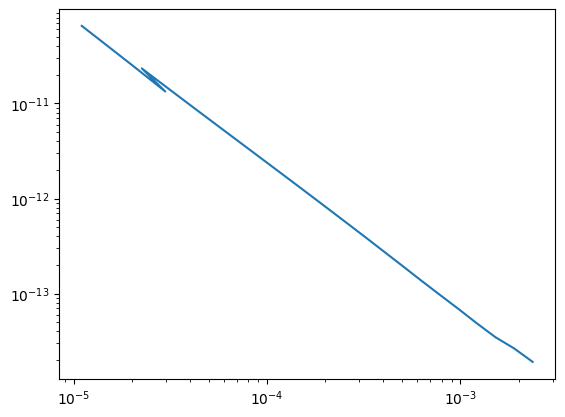

In [15]:
import matplotlib.pyplot as plt
plt.figure()
plt.loglog(dmfwr.times, dbdt)

In [16]:
df_data['sys_gate'] = df_data['system_id'].astype(str) + '-' + df_data['gate_id'].astype(str)

# Pivot the table: index by site_id and time, columns by sys_gate, values as dbdt
pivot = df_data.pivot_table(
    index=['site_id'],
    columns='sys_gate',
    values='dbdt'
)

# To reset the index and get a flat DataFrame:
# pivot = pivot.reset_index()
pivot

sys_gate,0-0,0-1,0-10,0-11,0-12,0-13,0-14,0-15,0-16,0-17,...,0-6,0-7,0-8,0-9,1-0,1-1,1-2,1-3,1-4,1-5
site_id,,,,,,,,,,,,,,,,,,,,,
0,9.116640e-07,5.378730e-07,4.208960e-09,2.467330e-09,1.436920e-09,8.203830e-10,4.772170e-10,2.667760e-10,1.538750e-10,8.745530e-11,...,3.478940e-08,2.047700e-08,1.212100e-08,7.128620e-09,0.000004,2.760710e-06,1.846710e-06,1.192260e-06,7.522400e-07,4.654560e-07
1,1.651910e-06,9.915630e-07,6.873840e-09,3.839090e-09,2.143800e-09,1.186390e-09,6.635700e-10,3.623920e-10,1.963990e-10,1.105150e-10,...,6.575960e-08,3.779390e-08,2.157480e-08,1.222330e-08,0.000007,4.783670e-06,3.263760e-06,2.150200e-06,1.379020e-06,8.660170e-07
2,9.936670e-07,5.920150e-07,4.734570e-09,2.741440e-09,1.590380e-09,9.112610e-10,5.235990e-10,3.016290e-10,1.718720e-10,9.869990e-11,...,4.022840e-08,2.366470e-08,1.389290e-08,8.124030e-09,0.000005,3.045990e-06,2.003670e-06,1.295030e-06,8.228180e-07,5.134000e-07
3,7.381810e-07,4.019250e-07,4.145300e-09,2.589620e-09,1.600270e-09,9.823650e-10,5.966630e-10,3.519800e-10,2.158370e-10,1.252210e-10,...,2.712230e-08,1.681980e-08,1.054890e-08,6.652590e-09,0.000005,3.005540e-06,1.753680e-06,1.009750e-06,5.821790e-07,3.388940e-07
4,9.939980e-07,5.924060e-07,5.073850e-09,2.959290e-09,1.718050e-09,9.892410e-10,5.683930e-10,3.194200e-10,1.849100e-10,1.047970e-10,...,4.190540e-08,2.485790e-08,1.471770e-08,8.674720e-09,0.000005,3.176190e-06,2.038610e-06,1.296990e-06,8.195330e-07,5.131080e-07
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
82,6.284670e-07,3.867190e-07,4.817840e-09,2.895950e-09,1.741790e-09,1.033370e-09,6.118900e-10,3.626160e-10,2.132790e-10,1.244630e-10,...,3.377560e-08,2.087700e-08,1.291170e-08,7.921710e-09,0.000003,1.884940e-06,1.238940e-06,8.049560e-07,5.217260e-07,3.359090e-07
83,2.776100e-07,1.802920e-07,3.524840e-09,2.303700e-09,1.468720e-09,9.089000e-10,5.716540e-10,3.358580e-10,2.026670e-10,1.207250e-10,...,2.003990e-08,1.285020e-08,8.461260e-09,5.425880e-09,0.000001,7.419910e-07,5.101060e-07,3.430200e-07,2.324290e-07,1.565840e-07
84,8.621520e-07,5.058280e-07,5.331070e-09,3.178440e-09,1.888810e-09,1.109870e-09,6.433460e-10,3.692990e-10,2.125620e-10,1.203630e-10,...,3.859960e-08,2.357900e-08,1.441830e-08,8.818330e-09,0.000004,2.739020e-06,1.787710e-06,1.132950e-06,7.050770e-07,4.355550e-07


In [17]:
df_overview2 = df_data.pivot_table(
    index=['site_id'],
    values=['date', 'latitude', 'longitude', 'elevation'],
    aggfunc='first'
)#.reset_index()
df_overview2

,date,elevation,latitude,longitude
site_id,,,,
0,20250302.0,175.0,4.139798,42.043678
1,20250302.0,175.0,4.140683,42.038157
2,20250302.0,174.0,4.138498,42.037464
3,20250302.0,175.0,4.147465,42.054918
4,20250302.0,172.0,4.137890,42.037484
...,...,...,...,...
82,20250302.0,172.0,4.147927,42.058077
83,20250302.0,172.0,4.144398,42.052701
84,20250302.0,176.0,4.133293,42.037072
